<center><h1>Hong_Brandon_HW5</h1></center>
<br>
<br>

Name: Brandon Hong
<br>
Github Username: bwhong
<br>
USC ID: 3091232124

## 1. Decision Trees as Interpretable Models

Import packages

In [723]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.decomposition import PCA
from xgboost import XGBRegressor

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

### (a) Obtain Data

Get the Accute Inamations Data Set

In [724]:
columns = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains', 'burning_uretha', 'bladder_inflamation', 'nephritis']

In [725]:
data = pd.read_csv(r'../data/diagnosis.data', header = None, sep="\t", decimal=",", encoding="utf-16", names=columns)
data.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_uretha,bladder_inflamation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


In [726]:
for i in data.columns[1:]:
    data[i] = data[i].map({'yes':1, 'no':0})
data.head(3)

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_uretha,bladder_inflamation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0


In [727]:
data['bladder_inflation-nephritis'] = data['bladder_inflamation'].astype(str) + '-' + data['nephritis'].astype(str)
data = data.drop(columns = {'bladder_inflamation', 'nephritis'})
data

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_uretha,bladder_inflation-nephritis
0,35.5,0,1,0,0,0,0-0
1,35.9,0,0,1,1,1,1-0
2,35.9,0,1,0,0,0,0-0
3,36.0,0,0,1,1,1,1-0
4,36.0,0,1,0,0,0,0-0
...,...,...,...,...,...,...,...
115,41.4,0,1,1,0,1,0-1
116,41.5,0,0,0,0,0,0-0
117,41.5,1,1,0,1,0,0-1
118,41.5,0,1,1,0,1,0-1


### (b) Build a decision tree

In [728]:
X = data.drop(columns = {'bladder_inflation-nephritis'})
y = data['bladder_inflation-nephritis']
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X,y)

DecisionTreeClassifier()

[Text(0.4, 0.9, 'lumbar_pain <= 0.5\ngini = 0.735\nsamples = 120\nvalue = [30.0, 31.0, 40.0, 19.0]\nclass = 1-0'),
 Text(0.2, 0.7, 'urine_pushing <= 0.5\ngini = 0.32\nsamples = 50\nvalue = [10, 0, 40, 0]\nclass = 1-0'),
 Text(0.30000000000000004, 0.8, 'True  '),
 Text(0.1, 0.5, 'gini = 0.0\nsamples = 10\nvalue = [10, 0, 0, 0]\nclass = 0-0'),
 Text(0.3, 0.5, 'gini = 0.0\nsamples = 40\nvalue = [0, 0, 40, 0]\nclass = 1-0'),
 Text(0.6, 0.7, 'temperature <= 37.95\ngini = 0.649\nsamples = 70\nvalue = [20, 31, 0, 19]\nclass = 0-1'),
 Text(0.5, 0.8, '  False'),
 Text(0.5, 0.5, 'gini = 0.0\nsamples = 20\nvalue = [20, 0, 0, 0]\nclass = 0-0'),
 Text(0.7, 0.5, 'nausea <= 0.5\ngini = 0.471\nsamples = 50\nvalue = [0, 31, 0, 19]\nclass = 0-1'),
 Text(0.6, 0.3, 'gini = 0.0\nsamples = 21\nvalue = [0, 21, 0, 0]\nclass = 0-1'),
 Text(0.8, 0.3, 'urine_pushing <= 0.5\ngini = 0.452\nsamples = 29\nvalue = [0, 10, 0, 19]\nclass = 1-1'),
 Text(0.7, 0.1, 'gini = 0.0\nsamples = 10\nvalue = [0, 10, 0, 0]\nclass =

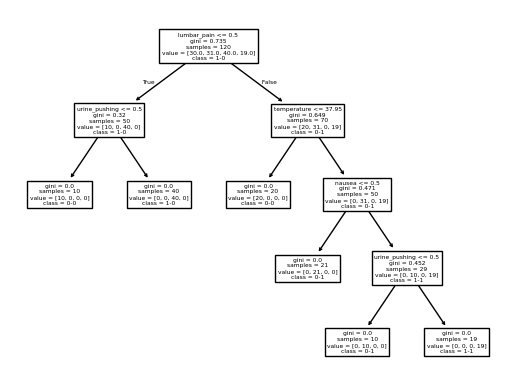

In [729]:
plot_tree(decision_tree, feature_names= X.columns, class_names=decision_tree.classes_ )

### (c) Convert the decision rules

In [730]:
def tree_to_code(tree, feature_names):
	"""
	Outputs a decision tree model as a Python function
	
	Parameters:
	-----------
	tree: decision tree model
		The decision tree to represent as a function
	feature_names: list
		The feature names of the dataset used for building the decision tree
	"""

	tree_ = tree.tree_
	feature_name = [
		feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
		for i in tree_.feature
	]
	print("def tree({}):".format(", ".join(feature_names)))

	def recurse(node, depth):
		indent = "  " * depth
		if tree_.feature[node] != _tree.TREE_UNDEFINED:
			name = feature_name[node]
			threshold = tree_.threshold[node]
			print("{}if {} <= {}:".format(indent, name, threshold))
			recurse(tree_.children_left[node], depth + 1)
			print("{}else:  # if {} > {}".format(indent, name, threshold))
			recurse(tree_.children_right[node], depth + 1)
		else:
			print("{}return {}".format(indent, tree_.value[node]))

	recurse(0, 1)

In [731]:
tree_to_code(decision_tree, feature_names= X.columns)

def tree(temperature, nausea, lumbar_pain, urine_pushing, micturition_pains, burning_uretha):
  if lumbar_pain <= 0.5:
    if urine_pushing <= 0.5:
      return [[1. 0. 0. 0.]]
    else:  # if urine_pushing > 0.5
      return [[0. 0. 1. 0.]]
  else:  # if lumbar_pain > 0.5
    if temperature <= 37.95000076293945:
      return [[1. 0. 0. 0.]]
    else:  # if temperature > 37.95000076293945
      if nausea <= 0.5:
        return [[0. 1. 0. 0.]]
      else:  # if nausea > 0.5
        if urine_pushing <= 0.5:
          return [[0. 1. 0. 0.]]
        else:  # if urine_pushing > 0.5
          return [[0. 0. 0. 1.]]


### (d) Cost Complexity Pruning

In [732]:
param_grid = {
    "ccp_alpha": [0, 0.0001, 0.001, 0.01, 0.1, 1]
}

decision_tree = DecisionTreeClassifier()
decision_tree_grid_search = GridSearchCV(decision_tree, param_grid, cv = 5, scoring='accuracy')
decision_tree_grid_search.fit(X,y)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'ccp_alpha': [0, 0.0001, 0.001, 0.01, 0.1, 1]},
             scoring='accuracy')

In [733]:
decision_tree_grid_search.best_estimator_

DecisionTreeClassifier(ccp_alpha=0)

[Text(0.4, 0.9, 'lumbar_pain <= 0.5\ngini = 0.735\nsamples = 120\nvalue = [30.0, 31.0, 40.0, 19.0]\nclass = 1-0'),
 Text(0.2, 0.7, 'temperature <= 38.95\ngini = 0.32\nsamples = 50\nvalue = [10, 0, 40, 0]\nclass = 1-0'),
 Text(0.30000000000000004, 0.8, 'True  '),
 Text(0.1, 0.5, 'gini = 0.0\nsamples = 40\nvalue = [0, 0, 40, 0]\nclass = 1-0'),
 Text(0.3, 0.5, 'gini = 0.0\nsamples = 10\nvalue = [10, 0, 0, 0]\nclass = 0-0'),
 Text(0.6, 0.7, 'temperature <= 37.95\ngini = 0.649\nsamples = 70\nvalue = [20, 31, 0, 19]\nclass = 0-1'),
 Text(0.5, 0.8, '  False'),
 Text(0.5, 0.5, 'gini = 0.0\nsamples = 20\nvalue = [20, 0, 0, 0]\nclass = 0-0'),
 Text(0.7, 0.5, 'nausea <= 0.5\ngini = 0.471\nsamples = 50\nvalue = [0, 31, 0, 19]\nclass = 0-1'),
 Text(0.6, 0.3, 'gini = 0.0\nsamples = 21\nvalue = [0, 21, 0, 0]\nclass = 0-1'),
 Text(0.8, 0.3, 'urine_pushing <= 0.5\ngini = 0.452\nsamples = 29\nvalue = [0, 10, 0, 19]\nclass = 1-1'),
 Text(0.7, 0.1, 'gini = 0.0\nsamples = 10\nvalue = [0, 10, 0, 0]\nclass =

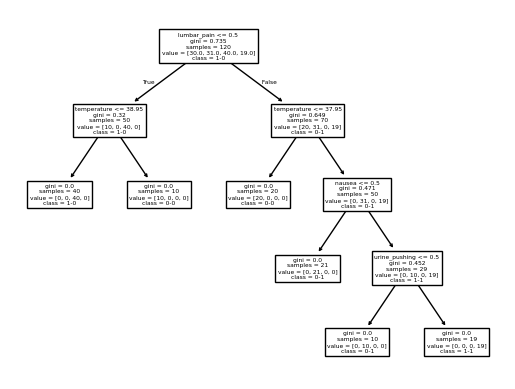

In [734]:
best_tree = decision_tree_grid_search.best_estimator_
plot_tree(best_tree, feature_names= X.columns, class_names=best_tree.classes_ )

In [735]:
tree_to_code(best_tree, feature_names= X.columns)

def tree(temperature, nausea, lumbar_pain, urine_pushing, micturition_pains, burning_uretha):
  if lumbar_pain <= 0.5:
    if temperature <= 38.95000076293945:
      return [[0. 0. 1. 0.]]
    else:  # if temperature > 38.95000076293945
      return [[1. 0. 0. 0.]]
  else:  # if lumbar_pain > 0.5
    if temperature <= 37.95000076293945:
      return [[1. 0. 0. 0.]]
    else:  # if temperature > 37.95000076293945
      if nausea <= 0.5:
        return [[0. 1. 0. 0.]]
      else:  # if nausea > 0.5
        if urine_pushing <= 0.5:
          return [[0. 1. 0. 0.]]
        else:  # if urine_pushing > 0.5
          return [[0. 0. 0. 1.]]


The minimal decision tree is the same as the unpruned decision tree. This means that removing any splits would reduced mean cross validation accuracy. Therefore, the unpruned tree provides the best accuracy and most interpretability. 

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [736]:
column_names = []

with open("../data/communities.names", encoding="utf-8") as file:
    for line in file:
        if line.lower().startswith("@attribute"):
            column_names.append(line.split()[1])


In [737]:
communities = pd.read_csv(r'../data/communities.csv', header = None, names = column_names, na_values='?')
communities.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [738]:
train_data = communities.iloc[:1495, :]
train_data.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [739]:
test_data = communities.iloc[1495:, :]
test_data.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
1495,6,NaN,NaN,MillValleycity,8,0.00,0.20,0.03,0.91,0.23,...,0.01,0.23,0.73,NaN,NaN,NaN,NaN,0.0,NaN,0.12
1496,48,NaN,NaN,LiveOakcity,8,0.00,0.55,0.13,0.78,0.15,...,0.01,0.18,0.02,NaN,NaN,NaN,NaN,0.0,NaN,0.11
1497,35,NaN,NaN,Portalescity,8,0.00,0.52,0.04,0.59,0.05,...,0.01,0.18,0.00,NaN,NaN,NaN,NaN,0.0,NaN,0.12
1498,42,17.0,25112.0,Fallstownship,8,0.04,0.51,0.07,0.92,0.09,...,0.06,0.13,0.16,NaN,NaN,NaN,NaN,0.0,NaN,0.06
1499,51,683.0,48952.0,Manassascity,8,0.03,0.59,0.20,0.75,0.19,...,0.03,0.23,0.06,NaN,NaN,NaN,NaN,0.0,NaN,0.12


### (b) Missing values

nonpredictive = state, county, community, communityname, fold

In [740]:
train_data = train_data.drop(columns = {'state', 'county', 'community', 'communityname', 'fold'})

In [741]:
train_data.shape

(1495, 123)

In [742]:
train_data.isna().sum()[train_data.isna().sum() > 0]

OtherPerCap                1
LemasSwornFT            1256
LemasSwFTPerPop         1256
LemasSwFTFieldOps       1256
LemasSwFTFieldPerPop    1256
LemasTotalReq           1256
LemasTotReqPerPop       1256
PolicReqPerOffic        1256
PolicPerPop             1256
RacialMatchCommPol      1256
PctPolicWhite           1256
PctPolicBlack           1256
PctPolicHisp            1256
PctPolicAsian           1256
PctPolicMinor           1256
OfficAssgnDrugUnits     1256
NumKindsDrugsSeiz       1256
PolicAveOTWorked        1256
PolicCars               1256
PolicOperBudg           1256
LemasPctPolicOnPatr     1256
LemasGangUnitDeploy     1256
PolicBudgPerPop         1256
dtype: int64

In [743]:
train_data[~train_data['OtherPerCap'].isnull()]['OtherPerCap'].value_counts().head()

OtherPerCap
0.00    100
0.20     56
0.16     52
0.22     50
0.25     48
Name: count, dtype: int64

(array([178., 294., 487., 249., 132.,  61.,  31.,  18.,  13.,  31.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

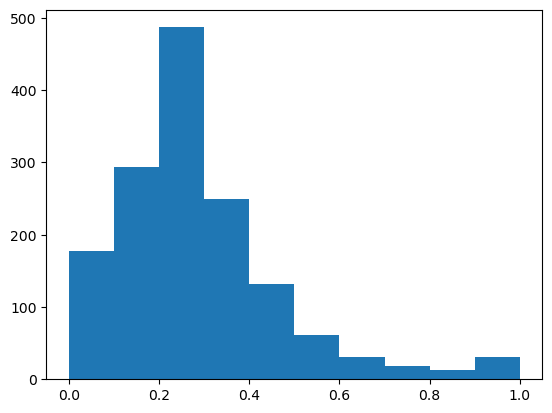

In [744]:
plt.hist(train_data['OtherPerCap'])

In [745]:
1256/1495

0.8401337792642141

In [746]:
#median imputation
train_data['OtherPerCap'] = train_data['OtherPerCap'].fillna(train_data['OtherPerCap'].median())

In [747]:
train_data = train_data.drop(columns = {'LemasSwornFT', 'LemasSwFTPerPop', 'LemasSwFTFieldOps', 'LemasSwFTFieldPerPop', 'LemasTotalReq', 'LemasTotReqPerPop', 'PolicReqPerOffic', 'PolicPerPop', 'RacialMatchCommPol', 'PctPolicWhite', 'PctPolicBlack', 'PctPolicHisp', 'PctPolicAsian', 'PctPolicMinor', 'OfficAssgnDrugUnits', 'NumKindsDrugsSeiz', 'PolicAveOTWorked', 'PolicCars', 'PolicOperBudg', 'LemasPctPolicOnPatr', 'LemasGangUnitDeploy', 'LemasGangUnitDeploy', 'PolicBudgPerPop'})
train_data.head()

,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn,ViolentCrimesPerPop
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.12,0.42,0.50,0.51,0.64,0.12,0.26,0.20,0.32,0.20
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,0.21,0.50,0.34,0.60,0.52,0.02,0.12,0.45,0.00,0.67
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.00,0.43
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,0.19,0.30,0.73,0.64,0.65,0.02,0.39,0.28,0.00,0.12
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,0.11,0.72,0.64,0.61,0.53,0.04,0.09,0.02,0.00,0.03


### (c) Plot a correlation matrix

In [748]:
corr_matrix = train_data.corr(method="pearson")

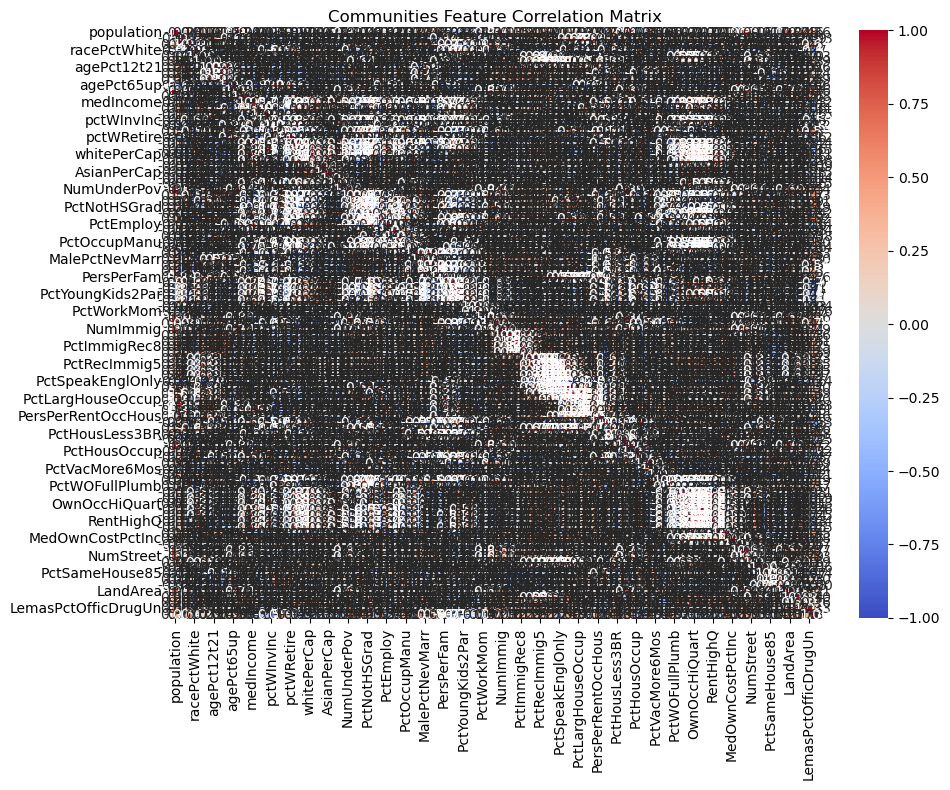

In [749]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",  
    fmt=".2f", 
    vmin=-1,
    vmax=1
)

plt.title("Communities Feature Correlation Matrix")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [750]:
X_train = train_data.drop(columns = {'ViolentCrimesPerPop'})
y_train = train_data['ViolentCrimesPerPop']

In [751]:
cv_list = []
for i in X_train:
    std = X_train[i].std()
    mean = X_train[i].mean()
    cv = std / mean
    cv_list.append(cv)
cv_list[:5]

[np.float64(2.241104624580381),
 np.float64(0.35579956640289406),
 np.float64(1.4288854186502817),
 np.float64(0.3302126634442842),
 np.float64(1.3590996841590066)]

In [752]:
data = {'Feature Names': X_train.columns, 'Coefficient of Variation': cv_list}
cv_df = pd.DataFrame(data)
cv_df.head()

,Feature Names,Coefficient of Variation
0,population,2.241105
1,householdsize,0.355800
2,racepctblack,1.428885
3,racePctWhite,0.330213
4,racePctAsian,1.359100


### (e) Scatter plots and box plots for highest CV features

In [753]:
128**(1/2)

11.313708498984761

In [754]:
cv_df_top_features = cv_df.sort_values('Coefficient of Variation', ascending=False).head(11)
cv_df_top_features

,Feature Names,Coefficient of Variation
90,NumStreet,4.292923
89,NumInShelters,3.470952
49,NumIlleg,3.058964
51,NumImmig,2.926635
99,LemasPctOfficDrugUn,2.552946
27,NumUnderPov,2.342443
0,population,2.241105
10,numbUrban,2.038461
71,HousVacant,1.968467
96,LandArea,1.645408


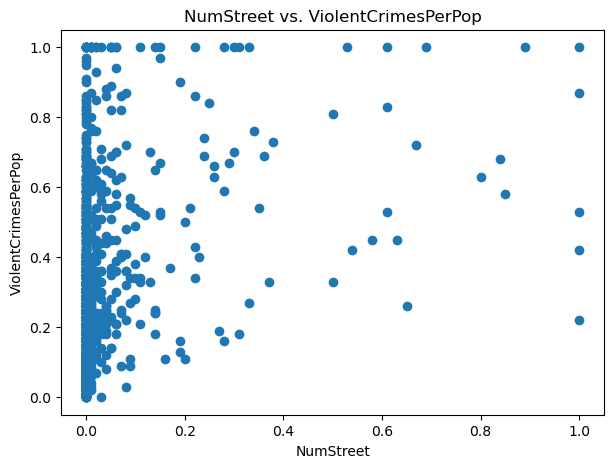

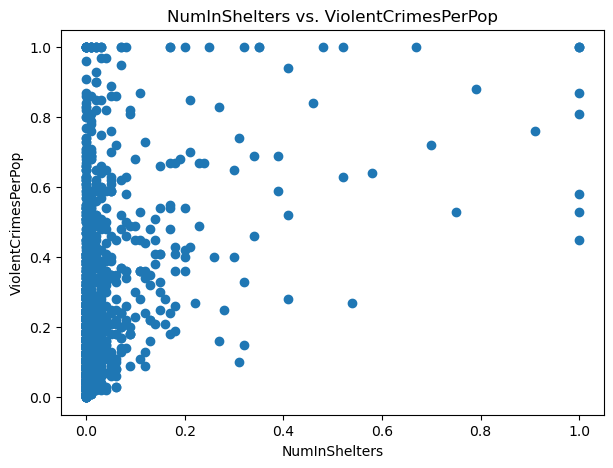

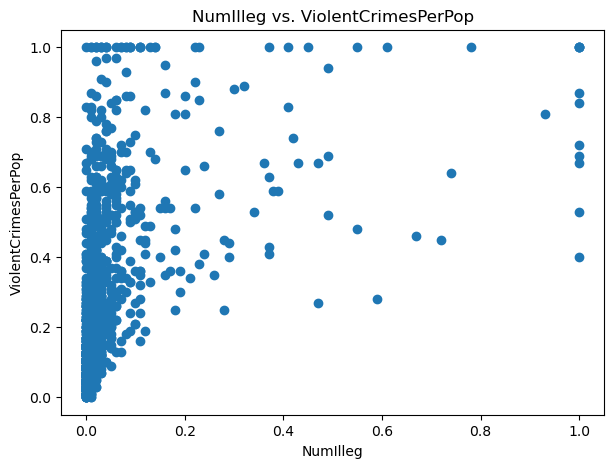

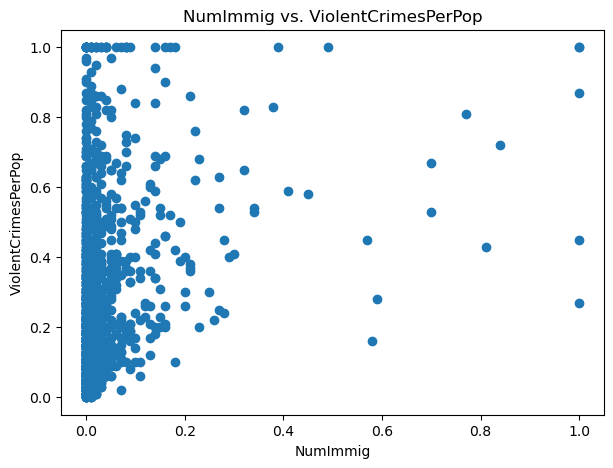

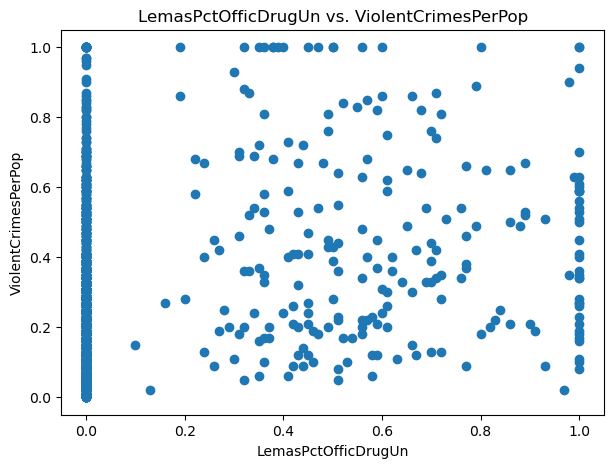

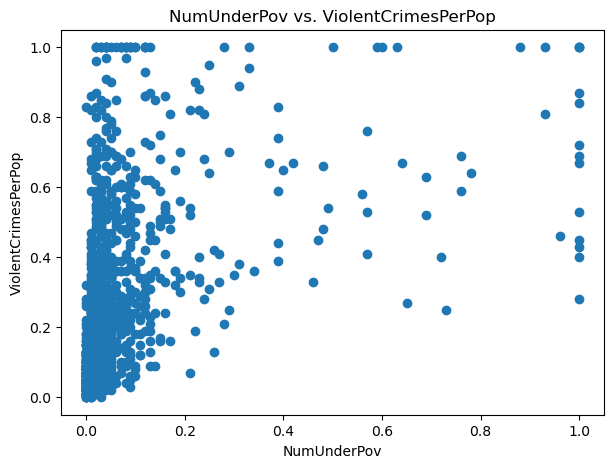

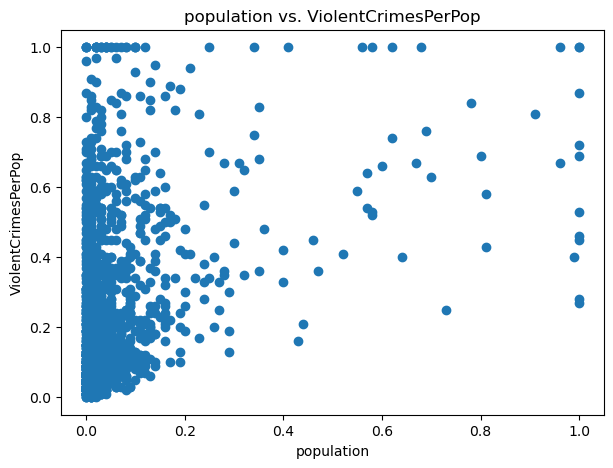

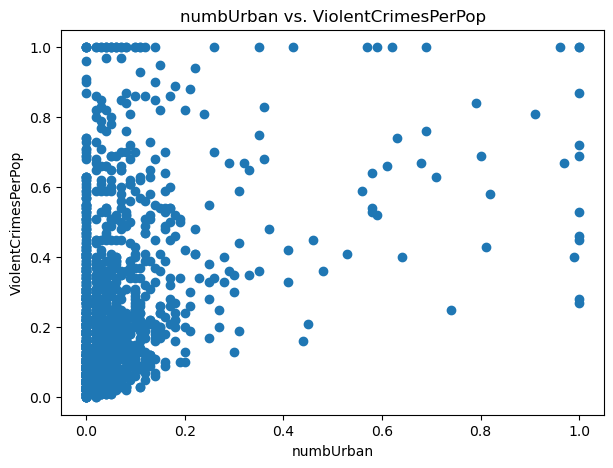

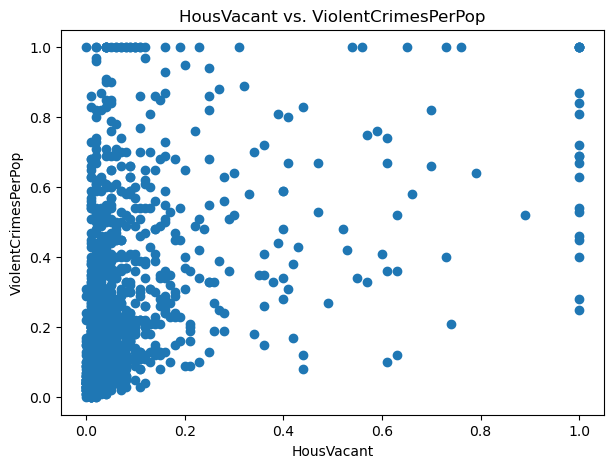

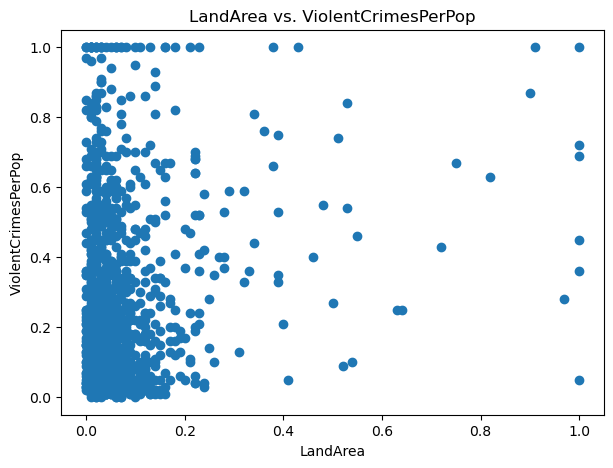

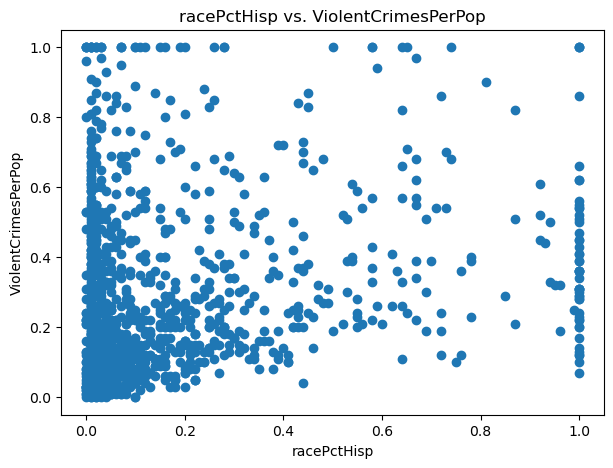

In [755]:
for i in cv_df_top_features['Feature Names']:
    plt.figure(figsize=(7, 5))
    plt.scatter(X_train[i], y_train)
    plt.xlabel(f'{i}')
    plt.ylabel('ViolentCrimesPerPop')
    plt.title(f'{i} vs. ViolentCrimesPerPop')

Text(0.5, 1.0, 'Communities Dataset Top 11 Boxplot')

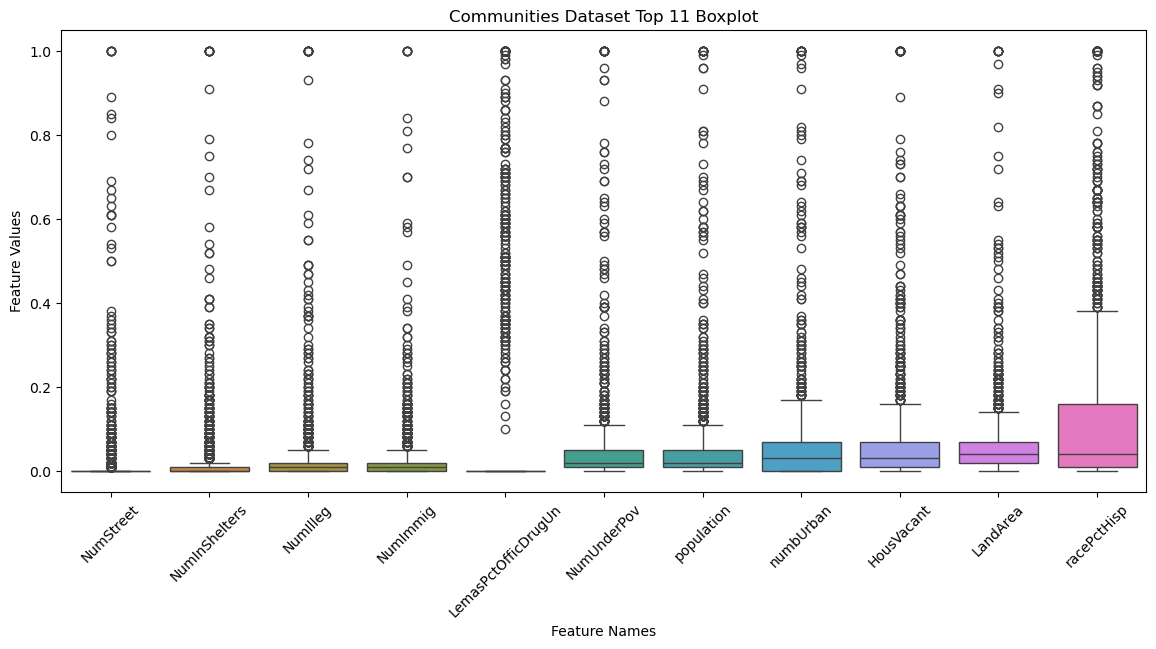

In [756]:
plt.figure(figsize=(14, 6))
sns.boxplot(data = X_train[cv_df_top_features['Feature Names']])
plt.xticks(rotation = 45)
plt.xlabel('Feature Names')
plt.ylabel('Feature Values')
plt.title('Communities Dataset Top 11 Boxplot')

From the scatter plots, it is difficult to come up with a decision about the significance of the features. It would appear that there may be a relationship that is right skewed by outliers. The boxplots also support this, where nearly all of the top 11 features are concentrated near 0. All the circles are outliers, and there are numerous outliers per feature. The high CV only suggests that there is high variability compared to the mean, which is not the same as a strong relationship between ViolentCrimesPerPop. There is maybe a weak relationship between some of the features, but we would need statisitcal tests to confidently say there is significance. 

### (f) Fit a linear model

##### Clean Test Data

In [757]:
test_data.isna().sum()[test_data.isna().sum() > 0]

county                  296
community               297
LemasSwornFT            419
LemasSwFTPerPop         419
LemasSwFTFieldOps       419
LemasSwFTFieldPerPop    419
LemasTotalReq           419
LemasTotReqPerPop       419
PolicReqPerOffic        419
PolicPerPop             419
RacialMatchCommPol      419
PctPolicWhite           419
PctPolicBlack           419
PctPolicHisp            419
PctPolicAsian           419
PctPolicMinor           419
OfficAssgnDrugUnits     419
NumKindsDrugsSeiz       419
PolicAveOTWorked        419
PolicCars               419
PolicOperBudg           419
LemasPctPolicOnPatr     419
LemasGangUnitDeploy     419
PolicBudgPerPop         419
dtype: int64

In [758]:
test_data = test_data.drop(columns = {'state', 'county', 'community', 'communityname', 'fold', 'LemasSwornFT', 'LemasSwFTPerPop', 'LemasSwFTFieldOps', 'LemasSwFTFieldPerPop', 'LemasTotalReq', 'LemasTotReqPerPop', 'PolicReqPerOffic', 'PolicPerPop', 'RacialMatchCommPol', 'PctPolicWhite', 'PctPolicBlack', 'PctPolicHisp', 'PctPolicAsian', 'PctPolicMinor', 'OfficAssgnDrugUnits', 'NumKindsDrugsSeiz', 'PolicAveOTWorked', 'PolicCars', 'PolicOperBudg', 'LemasPctPolicOnPatr', 'LemasGangUnitDeploy', 'LemasGangUnitDeploy', 'PolicBudgPerPop'})
test_data.head()

,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn,ViolentCrimesPerPop
1495,0.00,0.20,0.03,0.91,0.23,0.05,0.15,0.19,0.09,0.42,...,0.33,0.45,0.57,0.56,0.74,0.01,0.23,0.73,0.0,0.12
1496,0.00,0.55,0.13,0.78,0.15,0.36,0.48,0.53,0.30,0.10,...,0.17,0.45,0.52,0.59,0.57,0.01,0.18,0.02,0.0,0.11
1497,0.00,0.52,0.04,0.59,0.05,0.62,0.84,0.78,0.75,0.43,...,0.19,0.47,0.37,0.38,0.49,0.01,0.18,0.00,0.0,0.12
1498,0.04,0.51,0.07,0.92,0.09,0.03,0.38,0.47,0.27,0.35,...,0.10,0.62,0.70,0.75,0.64,0.06,0.13,0.16,0.0,0.06
1499,0.03,0.59,0.20,0.75,0.19,0.10,0.38,0.62,0.35,0.11,...,0.22,0.33,0.16,0.06,0.27,0.03,0.23,0.06,0.0,0.12


In [759]:
X_test = test_data.drop(columns = 'ViolentCrimesPerPop')
y_test = test_data['ViolentCrimesPerPop']

##### Linear Model

In [760]:
linear_model = LinearRegression()
linear_model.fit(X_train,y_train)

LinearRegression()

In [761]:
y_pred = linear_model.predict(X_test)
linear_mse = mean_squared_error(y_test, y_pred)
print("Test Error:" , linear_mse)

Test Error: 0.01784392920945602


### (g) Fit a ridge regression model

In [762]:
param_grid = {'ridge__alpha': np.logspace(-4, 1, 100)}

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

ridgel_model = GridSearchCV(pipeline, param_grid, cv = 5, scoring = 'neg_mean_squared_error')
ridgel_model.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('ridge', Ridge())]),
             param_grid={'ridge__alpha': array([1.00000000e-04, 1.12332403e-04, 1.26185688e-04, 1.41747416e-04,
       1.59228279e-04, 1.78864953e-04, 2.00923300e-04, 2.25701972e-04,
       2.53536449e-04, 2.84803587e-04, 3.19926714e-04, 3.59381366e-04,
       4.03701726e-04, 4.53487851e-04, 5.09413801e-04...
       6.89261210e-01, 7.74263683e-01, 8.69749003e-01, 9.77009957e-01,
       1.09749877e+00, 1.23284674e+00, 1.38488637e+00, 1.55567614e+00,
       1.74752840e+00, 1.96304065e+00, 2.20513074e+00, 2.47707636e+00,
       2.78255940e+00, 3.12571585e+00, 3.51119173e+00, 3.94420606e+00,
       4.43062146e+00, 4.97702356e+00, 5.59081018e+00, 6.28029144e+00,
       7.05480231e+00, 7.92482898e+00, 8.90215085e+00, 1.00000000e+01])},
             scoring='neg_mean_squared_error')

In [763]:
ridgel_model.best_params_["ridge__alpha"]

np.float64(10.0)

In [764]:
y_pred = ridgel_model.predict(X_test)
ridge_mse = mean_squared_error(y_test, y_pred)
print("Test Error:" , ridge_mse)

Test Error: 0.01759897004541483


### (h) Fit a LASSO model

In [765]:
param_grid = {'alpha': np.logspace(-4, 1, 100)}

unscaled_lasso = Lasso()
unscaled_lasso_model = GridSearchCV(unscaled_lasso, param_grid, cv = 5, scoring = 'neg_mean_squared_error')
unscaled_lasso_model.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=Lasso(),
             param_grid={'alpha': array([1.00000000e-04, 1.12332403e-04, 1.26185688e-04, 1.41747416e-04,
       1.59228279e-04, 1.78864953e-04, 2.00923300e-04, 2.25701972e-04,
       2.53536449e-04, 2.84803587e-04, 3.19926714e-04, 3.59381366e-04,
       4.03701726e-04, 4.53487851e-04, 5.09413801e-04, 5.72236766e-04,
       6.42807312e-04, 7.22080902e-04, 8.11130831e-04, 9....
       6.89261210e-01, 7.74263683e-01, 8.69749003e-01, 9.77009957e-01,
       1.09749877e+00, 1.23284674e+00, 1.38488637e+00, 1.55567614e+00,
       1.74752840e+00, 1.96304065e+00, 2.20513074e+00, 2.47707636e+00,
       2.78255940e+00, 3.12571585e+00, 3.51119173e+00, 3.94420606e+00,
       4.43062146e+00, 4.97702356e+00, 5.59081018e+00, 6.28029144e+00,
       7.05480231e+00, 7.92482898e+00, 8.90215085e+00, 1.00000000e+01])},
             scoring='neg_mean_squared_error')

In [766]:
unscaled_lasso_model.best_params_['alpha']

np.float64(0.00011233240329780277)

In [767]:
y_pred = unscaled_lasso_model.predict(X_test)
lasso_mse = mean_squared_error(y_test, y_pred)
print("Test Error:" , lasso_mse)

Test Error: 0.01757531748977006


In [768]:
best_lasso = unscaled_lasso_model.best_estimator_
best_lasso_coef_df = pd.DataFrame({'Feature Name': X_train.columns, 'Coefficient' : best_lasso.coef_})
print(best_lasso_coef_df[best_lasso_coef_df['Coefficient'] != 0]['Feature Name'].tolist())

['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'numbUrban', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn

##### Standardized Data

In [769]:
param_grid = {'lasso__alpha': np.logspace(-4, 1, 100)}

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso())
])
lasso_model = GridSearchCV(pipeline, param_grid, cv = 5, scoring = 'neg_mean_squared_error')
lasso_model.fit(X_train, y_train)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.101e-02, tolerance: 6.791e-03
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.759e-02, tolerance: 6.607e-03
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.430e-02, toler

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('lasso', Lasso())]),
             param_grid={'lasso__alpha': array([1.00000000e-04, 1.12332403e-04, 1.26185688e-04, 1.41747416e-04,
       1.59228279e-04, 1.78864953e-04, 2.00923300e-04, 2.25701972e-04,
       2.53536449e-04, 2.84803587e-04, 3.19926714e-04, 3.59381366e-04,
       4.03701726e-04, 4.53487851e-04, 5.09413801e-04...
       6.89261210e-01, 7.74263683e-01, 8.69749003e-01, 9.77009957e-01,
       1.09749877e+00, 1.23284674e+00, 1.38488637e+00, 1.55567614e+00,
       1.74752840e+00, 1.96304065e+00, 2.20513074e+00, 2.47707636e+00,
       2.78255940e+00, 3.12571585e+00, 3.51119173e+00, 3.94420606e+00,
       4.43062146e+00, 4.97702356e+00, 5.59081018e+00, 6.28029144e+00,
       7.05480231e+00, 7.92482898e+00, 8.90215085e+00, 1.00000000e+01])},
             scoring='neg_mean_squared_error')

In [770]:
lasso_model.best_params_['lasso__alpha']

np.float64(0.0006428073117284319)

In [771]:
y_pred = lasso_model.predict(X_test)
lasso_mse = mean_squared_error(y_test, y_pred)
print("Test Error:" , lasso_mse)

Test Error: 0.017571823305083594


In [772]:
best_lasso = lasso_model.best_estimator_.named_steps["lasso"]
best_lasso_coef_df = pd.DataFrame({'Feature Name': X_train.columns, 'Coefficient' : best_lasso.coef_})
print(best_lasso_coef_df[best_lasso_coef_df['Coefficient'] != 0]['Feature Name'].tolist())

['population', 'racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctBornSameState', 'PctSameC

The non-standardized Lasso Model got a test MSE of  0.01757531748977006, while the standardized Lasso Model got a test MSE of 0.017571823305083594. They performed very similiarly, but the standardized Lasso Model performed slightly better since its test error is slightly lower.

### (i) Fit a PCR model

In [ ]:
param_grid = {'pca__n_components': np.arange(1,101,1)}

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ('linearregression', LinearRegression())
])
pcr_model = GridSearchCV(pipeline, param_grid, cv = 5, scoring = 'neg_mean_squared_error')
pcr_model.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('pca', PCA()),
                                       ('linearregression',
                                        LinearRegression())]),
             param_grid={'pca__n_components': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68,
       69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85,
       86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99])},
             scoring='neg_mean_squared_error')

In [784]:
pcr_model.best_params_['pca__n_components']

np.int64(77)

In [785]:
y_pred = pcr_model.predict(X_test)
pcr_mse = mean_squared_error(y_test, y_pred)
print("Test Error:" , pcr_mse)

Test Error: 0.018129536019057618


### (j) Fit a boosting tree

In [787]:
param_grid = {'reg_alpha': np.logspace(-4, 1, 100)}

xgboost_model = XGBRegressor(objective = 'reg:squarederror')

xgboost_model_grid_search = GridSearchCV(xgboost_model, param_grid, cv = 5, scoring = 'neg_mean_squared_error')
xgboost_model_grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=True, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_constraints=None,...
       6.89261210e-01, 7.74263683e-01, 8.69749003e-01, 9.77009957e-01,
       1.09749877e+00, 1.23284674e+00, 1.38488637e+00, 1.55567614e+00,
       1.74752840e+00, 1.96304065e+00, 2.20513074e+00, 2.47707636e+00,
       2.78255940e+00, 3.12571585e+00, 3.51119173e+00, 3.94420606e+00,
       4.43062146e+00, 4.97702356e+00, 5.59081018e+00, 6.28029144e+00,
       7.05480231e+00, 7.92482898e+00, 8.90215085e+00, 1.00000000e+01])},
             scoring='neg_mean_squared_error')

In [788]:
xgboost_model_grid_search.best_params_

{'reg_alpha': np.float64(1.3848863713938717)}

In [789]:
best_xgboost_model = xgboost_model_grid_search.best_estimator_

In [790]:
y_pred = best_xgboost_model.predict(X_test)
xgboost_mse = mean_squared_error(y_test, y_pred)
print("Test Error:" , xgboost_mse)

Test Error: 0.017207774996698094
